# Deployable Model

This notebook shows implementation of the Bayesian predictor for component K integrity.

It loads a pre-trained model `deployable_model.npz` and defines the `predict` function.

## Imports

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## The `Model` class

In [16]:
class Model:

    def __init__(self, npz_path="deployable_model.npz"):
        d = np.load(npz_path, allow_pickle=True)
        #Posterior samples
        self.u_samples = d["u_samples"]
        self.v_samples = d["v_samples"]
        self.w_samples = d["w_samples"]
        self.sigma_y_samples = d["sigma_y_samples"]
        self.X_mean = d["X_mean"]
        self.X_std = d["X_std"]
        self.X_raw = d["X_raw"]
        self.component_ids = d["component_ids"]
        self.X_norm = (self.X_raw - self.X_mean) / self.X_std

    @property
    def num_samples(self):
        return self.u_samples.shape[0]

    @property
    def num_components(self):
        return self.u_samples.shape[1]

## The `predict` function

In [17]:
def predict(index, day, model_obj):

    day_array = np.atleast_1d(np.asarray(day, dtype=float))
    scalar_input = (np.ndim(day) == 0)#is this a scalar or not?

    u_s = model_obj.u_samples[:, index]
    v_s = model_obj.v_samples[:, index]
    w_s = model_obj.w_samples
    x_i = model_obj.X_norm[index]

    decay_s = v_s + w_s @ x_i

    #f at every (sample, day)
    f_all = u_s[:, None] * np.exp(-decay_s[:, None] * day_array[None, :] / 100.0) #(S,T)

    pred_mean = f_all.mean(axis=0)
    pred_std  = f_all.std(axis=0)

    if scalar_input:
        return float(pred_mean[0]), float(pred_std[0])
    return pred_mean, pred_std

## Examples of Use

We load the model and the original data and demonstrate the predictor on a few components and for individual scalar day queries and vector day queries.

In [18]:
model_obj = Model("deployable_model.npz")
print(f"Loaded model: {model_obj.num_samples} posterior samples, "
      f"{model_obj.num_components} components")

df = pd.read_csv("bml-component-data.csv")

Loaded model: 8000 posterior samples, 75 components


### Scalar day: single day

In [19]:
mu, std = predict(index=3, day=30.0, model_obj=model_obj)
print(f"Component K#0003 at day 30:  mean = {mu:.2f}%   std = {std:.2f}%")

mu, std = predict(index=74, day=30.0, model_obj=model_obj)
print(f"Component K#0074 at day 30:  mean = {mu:.2f}%   std = {std:.2f}%")

Component K#0003 at day 30:  mean = 17.70%   std = 0.90%
Component K#0074 at day 30:  mean = 42.80%   std = 3.92%


### Vector day: many days

In [20]:
days = np.linspace(0, 30, 31)
mean74, std74 = predict(index=74, day=days, model_obj=model_obj)
print(f"Output shapes: mean {mean74.shape}, std {std74.shape}")
print(f"At t=30: mean = {mean74[30]:.2f}%, std = {std74[30]:.2f}%")

Output shapes: mean (31,), std (31,)
At t=30: mean = 42.80%, std = 3.92%


### Plot predictions for a few components

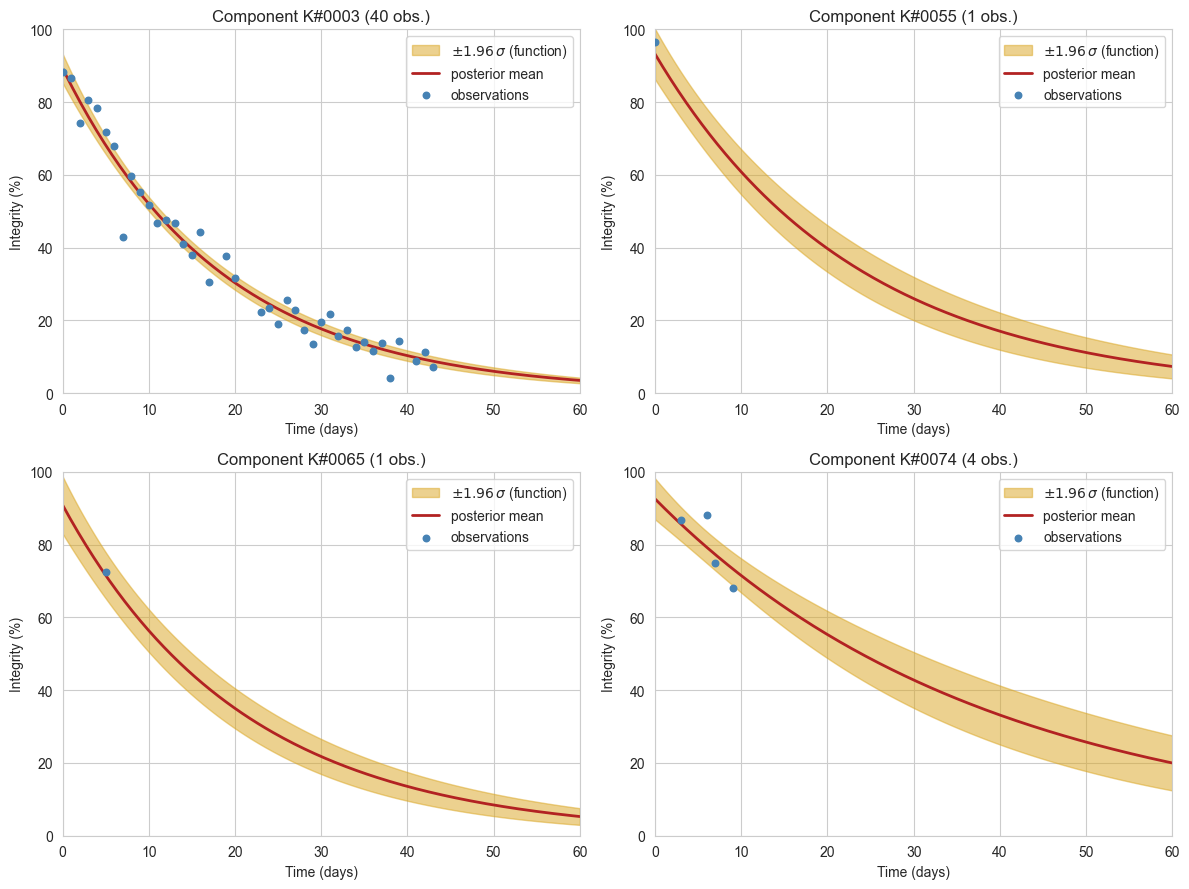

In [21]:
def plot_predictions(comp_indices, model_obj, df, t_max=60):
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    days = np.linspace(0, t_max, 200)
    for ax, idx in zip(axes.ravel(), comp_indices):
        pred_mean, pred_std = predict(idx, days, model_obj)
        rows = df[df["index"] == idx]
        ax.fill_between(days, pred_mean - 1.96 * pred_std, pred_mean + 1.96 * pred_std,
                        color="goldenrod", alpha=0.5,
                        label=r"$\pm 1.96\,\sigma$ (function)")
        ax.plot(days, pred_mean, color="Firebrick", lw=2, label="posterior mean")
        ax.scatter(rows["day"], rows["integrity"], s=22, color="Steelblue",
                   zorder=4, label="observations")
        ax.set_xlim(0, t_max)
        ax.set_ylim(0, 100)
        ax.set_xlabel("Time (days)")
        ax.set_ylabel("Integrity (%)")
        ax.set_title(f"Component {model_obj.component_ids[idx]} ({len(rows)} obs.)")
        ax.legend()
    plt.tight_layout()
    plt.show()


#One with lots of data and one with not much data
plot_predictions([3, 55, 65, 74], model_obj, df)